**Employee Turnover Classification**

**Overview:** This project utilizes human resources data to predict whether an employee will remain with the company or churn. Logistic Regression and Gradient Boosting Classification models are employed with the final model being selected based on cross validation scoring. Hyperparamter tuning is utilized to optimize model performance before fitting the final model to training data. Notebook sections include exploratory data analysis, visualization EDA, and machine learning. Finally, classification metrics are used to evaluate the final ML model.

In [1]:
print("Import Libraries")
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.impute import SimpleImputer

Import Libraries


In [2]:
print("Set Notebook & Plotting Options")
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8')
fontweight='bold'
fontsize=12
pd.options.display.float_format = '{:,.2f}'.format
%matplotlib inline
output_divider = '=' * 110

Set Notebook & Plotting Options


**Part 1: Initial EDA**

In [3]:
df = pd.read_csv(r"C:\Users\natha\OneDrive\Documents\DataSets\attrition train.csv")
print("First Five Rows Of Data:")
df.head()

First Five Rows Of Data:


,Unnamed: 0,id,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,0,0,36,Travel_Frequently,599,Research & Development,24,3,Medical,1,4,Male,42,3,1,Laboratory Technician,4,Married,2596,5099,1,Y,Yes,13,3,2,80,1,10,2,3,10,0,7,8,0
1,1,1,35,Travel_Rarely,921,Sales,8,3,Other,1,1,Male,46,3,1,Sales Representative,1,Married,2899,10778,1,Y,No,17,3,4,80,1,4,3,3,4,2,0,3,0
2,2,2,32,Travel_Rarely,718,Sales,26,3,Marketing,1,3,Male,80,3,2,Sales Executive,4,Divorced,4627,16495,0,Y,No,17,3,4,80,2,4,3,3,3,2,1,2,0
3,3,3,38,Travel_Rarely,1488,Research & Development,2,3,Medical,1,3,Female,40,3,2,Healthcare Representative,1,Married,5347,13384,3,Y,No,14,3,3,80,0,15,1,1,6,0,0,2,0
4,4,4,50,Travel_Rarely,1017,Research & Development,5,4,Medical,1,2,Female,37,3,5,Manager,1,Single,19033,19805,1,Y,Yes,13,3,3,80,0,31,0,3,31,14,4,10,1


In [4]:
for cols in df.columns:
    print(cols)

Unnamed: 0
id
Age
BusinessTravel
DailyRate
Department
DistanceFromHome
Education
EducationField
EmployeeCount
EnvironmentSatisfaction
Gender
HourlyRate
JobInvolvement
JobLevel
JobRole
JobSatisfaction
MaritalStatus
MonthlyIncome
MonthlyRate
NumCompaniesWorked
Over18
OverTime
PercentSalaryHike
PerformanceRating
RelationshipSatisfaction
StandardHours
StockOptionLevel
TotalWorkingYears
TrainingTimesLastYear
WorkLifeBalance
YearsAtCompany
YearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager
Attrition


In [5]:
print('Rename Features & Drop Redundant Columns:')
print(output_divider)
df= df.rename(columns={
    'Age': 'Employee_Age',
    'DistanceFromHome': 'Distance',
    'JobRole': 'Position',
    'NumCompaniesWorked': 'Prior_Employers',
    'TotalWorkingYears': 'Years_Experience',
})
df= df.drop(columns=['id', 'Unnamed: 0'], axis=1)
for cols in df.columns:
    print(cols)

Rename Features & Drop Redundant Columns:
Employee_Age
BusinessTravel
DailyRate
Department
Distance
Education
EducationField
EmployeeCount
EnvironmentSatisfaction
Gender
HourlyRate
JobInvolvement
JobLevel
Position
JobSatisfaction
MaritalStatus
MonthlyIncome
MonthlyRate
Prior_Employers
Over18
OverTime
PercentSalaryHike
PerformanceRating
RelationshipSatisfaction
StandardHours
StockOptionLevel
Years_Experience
TrainingTimesLastYear
WorkLifeBalance
YearsAtCompany
YearsInCurrentRole
YearsSinceLastPromotion
YearsWithCurrManager
Attrition


In [6]:
print("Dataframe Size:", df.size, '|', 'Dataframe Shape:', df.shape)
print(output_divider)
print("Data Types & Initial Missing Data Inspection:")
df.info()

Dataframe Size: 106998 | Dataframe Shape: (3147, 34)
Data Types & Initial Missing Data Inspection:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3147 entries, 0 to 3146
Data columns (total 34 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Employee_Age              3147 non-null   int64 
 1   BusinessTravel            3147 non-null   object
 2   DailyRate                 3147 non-null   int64 
 3   Department                3147 non-null   object
 4   Distance                  3147 non-null   int64 
 5   Education                 3147 non-null   int64 
 6   EducationField            3147 non-null   object
 7   EmployeeCount             3147 non-null   int64 
 8   EnvironmentSatisfaction   3147 non-null   int64 
 9   Gender                    3147 non-null   object
 10  HourlyRate                3147 non-null   int64 
 11  JobInvolvement            3147 non-null   int64 
 12  JobLevel                  3147 no

In [7]:
missing_data = df.isna().sum()
print("Confirm No Missing Data:")
print(missing_data)

Confirm No Missing Data:
Employee_Age                0
BusinessTravel              0
DailyRate                   0
Department                  0
Distance                    0
Education                   0
EducationField              0
EmployeeCount               0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
Position                    0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
Prior_Employers             0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
Years_Experience            0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSinceLastPromotion     0
YearsWithCurrMa

In [8]:
comments = 'No missing data needs to be imputed or dropped.'
print(comments)

No missing data needs to be imputed or dropped.


In [9]:
print("Summary Statistics On Numeric Features:")
df.describe()

Summary Statistics On Numeric Features:


,Employee_Age,DailyRate,Distance,Education,EmployeeCount,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,Prior_Employers,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,Years_Experience,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
count,"3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00","3,147.00"
mean,36.45,850.59,8.92,2.93,1.00,2.74,66.91,2.76,2.03,2.76,"6,339.40","14,556.60",2.63,15.05,3.14,2.73,80.00,0.76,10.98,2.76,2.77,6.90,4.18,2.08,4.16,0.14
std,8.82,390.86,7.96,1.03,0.00,1.09,19.88,0.68,1.09,1.10,"4,610.58","7,117.33",2.49,3.54,0.35,1.08,0.00,0.81,7.51,1.21,0.68,6.00,3.60,3.13,3.57,0.35
min,18.00,102.00,1.00,1.00,1.00,1.00,30.00,1.00,1.00,1.00,"1,009.00",636.00,0.00,11.00,3.00,1.00,80.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
25%,30.00,543.00,2.00,2.00,1.00,2.00,50.00,2.00,1.00,2.00,"2,888.00","8,306.00",1.00,12.00,3.00,2.00,80.00,0.00,6.00,2.00,2.00,3.00,2.00,0.00,2.00,0.00
50%,35.00,852.00,7.00,3.00,1.00,3.00,67.00,3.00,2.00,3.00,"4,877.00","14,908.00",1.00,14.00,3.00,3.00,80.00,1.00,9.00,3.00,3.00,5.00,3.00,1.00,3.00,0.00
75%,42.00,"1,198.50",13.00,4.00,1.00,4.00,84.00,3.00,3.00,4.00,"7,725.00","20,744.50",4.00,17.00,3.00,4.00,80.00,1.00,15.00,3.00,3.00,9.00,7.00,2.00,7.00,0.00
max,60.00,"3,921.00",29.00,15.00,1.00,4.00,100.00,4.00,7.00,4.00,"19,999.00","26,999.00",9.00,25.00,4.00,4.00,80.00,3.00,41.00,6.00,4.00,41.00,18.00,15.00,17.00,1.00


In [10]:
print("Summary Statistics On Categorical Features:")
df.describe(include='object')

Summary Statistics On Categorical Features:


,BusinessTravel,Department,EducationField,Gender,Position,MaritalStatus,Over18,OverTime
count,3147,3147,3147,3147,3147,3147,3147,3147
unique,3,3,6,2,9,3,1,2
top,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,2333,2128,1381,1946,681,1446,3147,2331


In [11]:
print("Categorical Data Inspection:")
print(output_divider)
print("Travel Statuses:", df['BusinessTravel'].unique().tolist())
print(output_divider)
print("Departments:", df['Department'].unique().tolist())
print(output_divider)
print("Education Fields:", df['EducationField'].unique().tolist())
print(output_divider)
print("Genders:", df['Gender'].unique().tolist())
print(output_divider)
print("Positions:", df['Position'].unique().tolist())
print(output_divider)
print("Marriage Statuses:", df['MaritalStatus'].unique().tolist())
print(output_divider)
print("Adult Statuses:", df['Over18'].unique().tolist())
print(output_divider)
print("Overtime Statuses:", df['OverTime'].unique().tolist())

Categorical Data Inspection:
Travel Statuses: ['Travel_Frequently', 'Travel_Rarely', 'Non-Travel']
Departments: ['Research & Development', 'Sales', 'Human Resources']
Education Fields: ['Medical', 'Other', 'Marketing', 'Life Sciences', 'Technical Degree', 'Human Resources']
Genders: ['Male', 'Female']
Positions: ['Laboratory Technician', 'Sales Representative', 'Sales Executive', 'Healthcare Representative', 'Manager', 'Manufacturing Director', 'Research Scientist', 'Human Resources', 'Research Director']
Marriage Statuses: ['Married', 'Divorced', 'Single']
Adult Statuses: ['Y']
Overtime Statuses: ['Yes', 'No']


In [12]:
comments = 'No spelling, spacing, or capitalization corrections are needed for categorical features.'
print(comments)

No spelling, spacing, or capitalization corrections are needed for categorical features.


**Part 2: Visualization EDA**

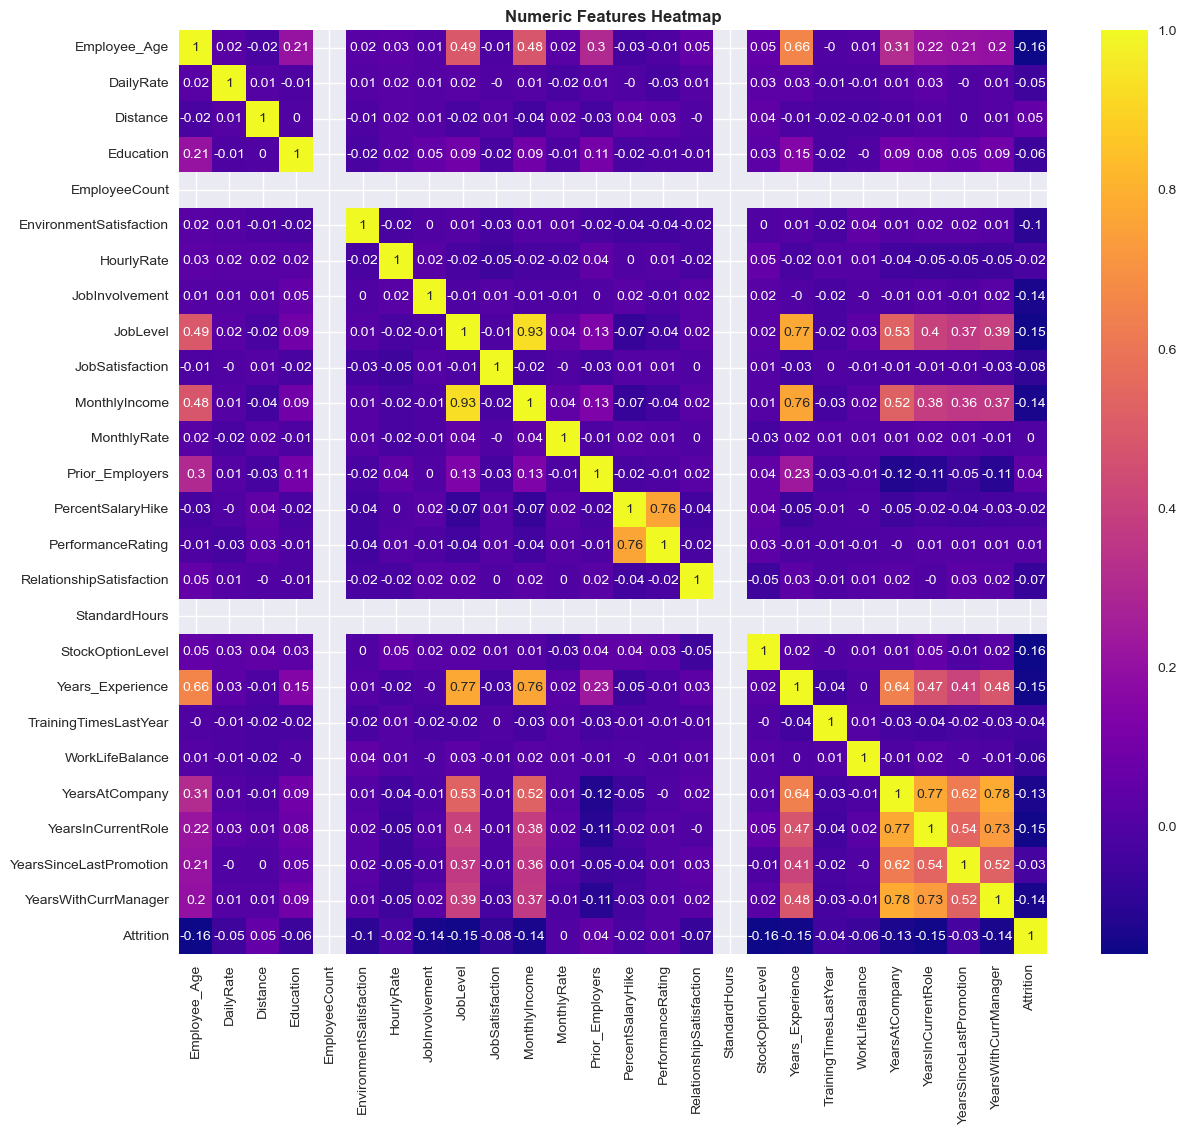

In [13]:
plt.figure(figsize=(14,12))
corr = df.select_dtypes(include=['int64', 'float64']).corr().round(2)
sns.heatmap(corr, cmap='plasma', annot=True)
plt.title("Numeric Features Heatmap", fontsize=fontsize,
          fontweight=fontweight)
plt.show()

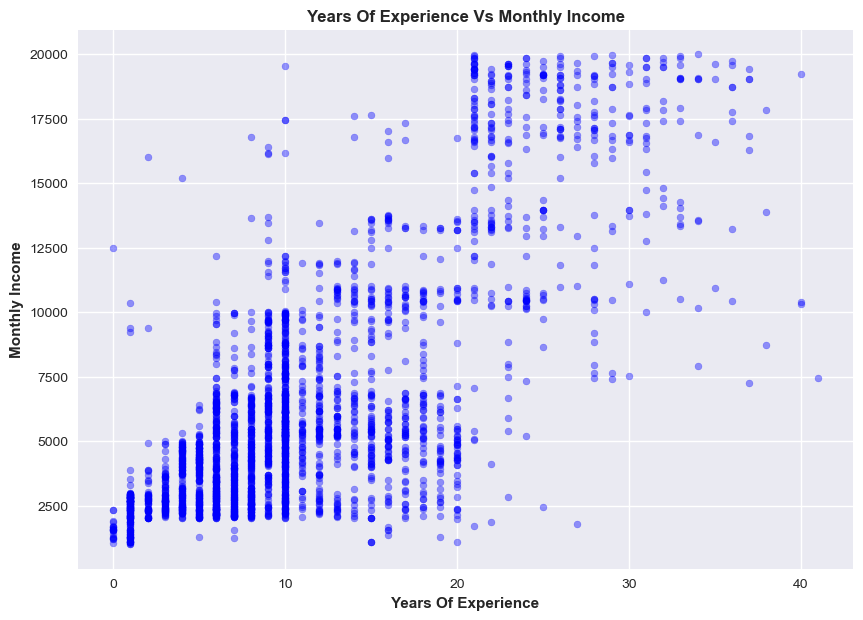

In [14]:
plt.figure(figsize=(10,7))
plt.scatter(x=df['Years_Experience'], y=df['MonthlyIncome'], alpha=0.4,
            color='blue', s=25)
plt.title("Years Of Experience Vs Monthly Income",
          fontsize=fontsize, fontweight=fontweight)
plt.xlabel("Years Of Experience", fontweight=fontweight)
plt.ylabel("Monthly Income", fontweight=fontweight)
plt.show()

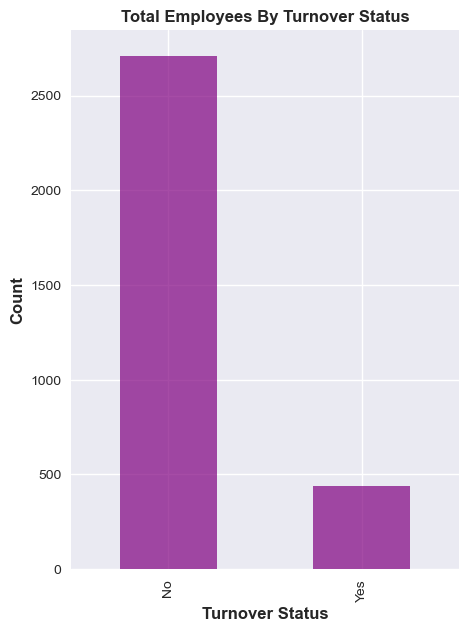

In [15]:
plt.figure(figsize=(5,7))
df['Turnover'] = df['Attrition'].map({0: 'No',
                         1: 'Yes'})
turnover= df['Turnover'].value_counts()
turnover.plot(kind='bar', color='purple', alpha=0.7)
plt.title("Total Employees By Turnover Status", fontweight=fontweight,
          fontsize=fontsize)
plt.xlabel("Turnover Status", fontweight=fontweight,
           fontsize=fontsize)
plt.ylabel("Count", fontweight=fontweight,
           fontsize=fontsize)
plt.show()

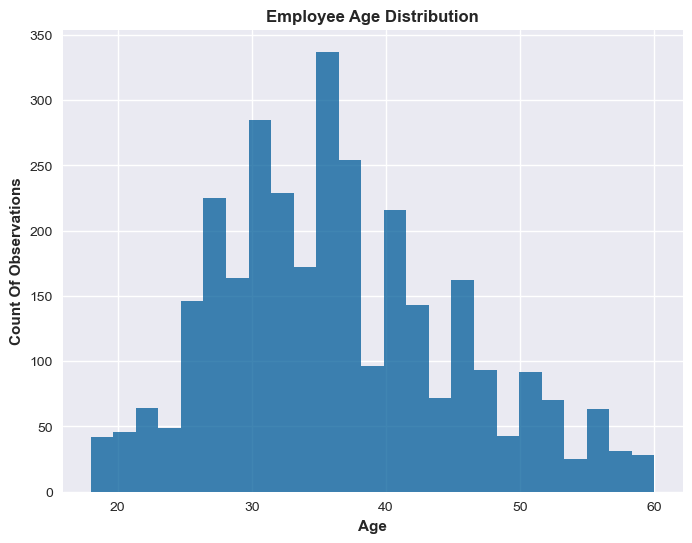

In [16]:
plt.figure(figsize=(8,6))
plt.hist(x=df['Employee_Age'], bins=25, color='#005c99', alpha=0.75)
plt.title("Employee Age Distribution", fontweight=fontweight, fontsize=fontsize)
plt.xlabel("Age", fontweight=fontweight)
plt.ylabel("Count Of Observations", fontweight=fontweight)
plt.show()

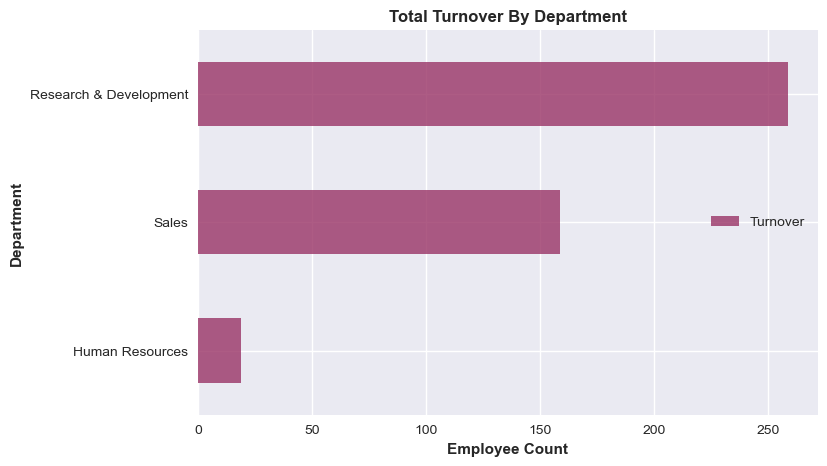

In [17]:
plt.figure(figsize=(8,5))
turnover_only = df.query("Turnover == 'Yes'")
turnover_department = turnover_only.groupby('Department')['Turnover'].count().sort_values(ascending=True)
turnover_department.plot(kind='barh', color='#993366', alpha=0.8, label='Turnover')
plt.title("Total Turnover By Department", fontsize=fontsize,
          fontweight=fontweight)
plt.xlabel("Employee Count", fontweight=fontweight)
plt.ylabel("Department", fontweight=fontweight)
plt.legend(loc='center right')
plt.show()

**Part 3: Machine Learning**

**3A: Data Preparation**

In [18]:
print("Data Types:")
print(df.dtypes)
print(output_divider)
df.head()

Data Types:
Employee_Age                 int64
BusinessTravel              object
DailyRate                    int64
Department                  object
Distance                     int64
Education                    int64
EducationField              object
EmployeeCount                int64
EnvironmentSatisfaction      int64
Gender                      object
HourlyRate                   int64
JobInvolvement               int64
JobLevel                     int64
Position                    object
JobSatisfaction              int64
MaritalStatus               object
MonthlyIncome                int64
MonthlyRate                  int64
Prior_Employers              int64
Over18                      object
OverTime                    object
PercentSalaryHike            int64
PerformanceRating            int64
RelationshipSatisfaction     int64
StandardHours                int64
StockOptionLevel             int64
Years_Experience             int64
TrainingTimesLastYear        int64
WorkLife

,Employee_Age,BusinessTravel,DailyRate,Department,Distance,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,Position,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,Prior_Employers,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,Years_Experience,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,Turnover
0,36,Travel_Frequently,599,Research & Development,24,3,Medical,1,4,Male,42,3,1,Laboratory Technician,4,Married,2596,5099,1,Y,Yes,13,3,2,80,1,10,2,3,10,0,7,8,0,No
1,35,Travel_Rarely,921,Sales,8,3,Other,1,1,Male,46,3,1,Sales Representative,1,Married,2899,10778,1,Y,No,17,3,4,80,1,4,3,3,4,2,0,3,0,No
2,32,Travel_Rarely,718,Sales,26,3,Marketing,1,3,Male,80,3,2,Sales Executive,4,Divorced,4627,16495,0,Y,No,17,3,4,80,2,4,3,3,3,2,1,2,0,No
3,38,Travel_Rarely,1488,Research & Development,2,3,Medical,1,3,Female,40,3,2,Healthcare Representative,1,Married,5347,13384,3,Y,No,14,3,3,80,0,15,1,1,6,0,0,2,0,No
4,50,Travel_Rarely,1017,Research & Development,5,4,Medical,1,2,Female,37,3,5,Manager,1,Single,19033,19805,1,Y,Yes,13,3,3,80,0,31,0,3,31,14,4,10,1,Yes


In [19]:
X = df.drop(columns=['Attrition', 'Turnover'], axis=1)
y = df['Attrition']
numeric_features = X.select_dtypes(include=['int64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()
print("Numeric Features:", numeric_features)
print(output_divider)
print("Categorical Features:", categorical_features)

Numeric Features: ['Employee_Age', 'DailyRate', 'Distance', 'Education', 'EmployeeCount', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'Prior_Employers', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'Years_Experience', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
Categorical Features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'Position', 'MaritalStatus', 'Over18', 'OverTime']


In [20]:
print("Set Random State, Cross Validations, & Split Training/Testing Data.")
random_state = 42
cv = KFold(n_splits=5, shuffle=True, random_state=random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=random_state, stratify=y,
                                                    test_size=0.20)

Set Random State, Cross Validations, & Split Training/Testing Data.


In [21]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler())])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore'))])

data_preprocessor = ColumnTransformer(transformers=[
    ('numeric', numeric_transformer, numeric_features),
    ('categorical', categorical_transformer, categorical_features)])

**3B: Logistic Regression**

In [22]:
LR_Pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Logistic_Regression', LogisticRegression(random_state=random_state, max_iter=1000))])

In [23]:
LR_Crossval_Untuned = cross_val_score(LR_Pipeline, X_train, y_train, scoring='f1', cv=cv)
LR_Crossval_Untuned_Mean = LR_Crossval_Untuned.mean()
print("Untuned Logistic Regression Cross Validation Scores:", LR_Crossval_Untuned)
print(output_divider)
print("Untuned Logistic Regression Mean Cross Validation Score:", LR_Crossval_Untuned_Mean)

Untuned Logistic Regression Cross Validation Scores: [0.44247788 0.48888889 0.3030303  0.42307692 0.36842105]
Untuned Logistic Regression Mean Cross Validation Score: 0.40517900874677776


**3C: Logistic Regression Hyperparameter Tuning**

In [24]:
print("Logistic Regression Hyperparameter Tuning:")
print(output_divider)
param_grid = {
    'Logistic_Regression__C': [0.01, 0.1, 1, 10, 100],
    'Logistic_Regression__class_weight': [None, 'balanced'],
    'Logistic_Regression__solver': ['lbfgs', 'liblinear']}

grid_search = GridSearchCV(LR_Pipeline, param_grid, cv=cv, scoring='f1')
grid_search.fit(X_train, y_train)
print("Optimal Logistic Regression Parameters:", grid_search.best_params_)

Logistic Regression Hyperparameter Tuning:
Optimal Logistic Regression Parameters: {'Logistic_Regression__C': 0.1, 'Logistic_Regression__class_weight': 'balanced', 'Logistic_Regression__solver': 'lbfgs'}


In [25]:
LR_Pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Logistic_Regression', LogisticRegression(random_state=random_state,
                                              C=0.1, class_weight='balanced', solver='lbfgs'))])

In [26]:
LR_Crossval_Tuned = cross_val_score(LR_Pipeline, X_train, y_train, scoring='f1', cv=cv)
LR_Crossval_Tuned_Mean = LR_Crossval_Tuned.mean()
print("Tuned Logistic Regression Cross Validation Scores:", LR_Crossval_Tuned)
print(output_divider)
print("Tuned Logistic Regression Mean Cross Validation Score:", LR_Crossval_Tuned_Mean)

Tuned Logistic Regression Cross Validation Scores: [0.475      0.44117647 0.49137931 0.43396226 0.47787611]
Tuned Logistic Regression Mean Cross Validation Score: 0.4638788302557392


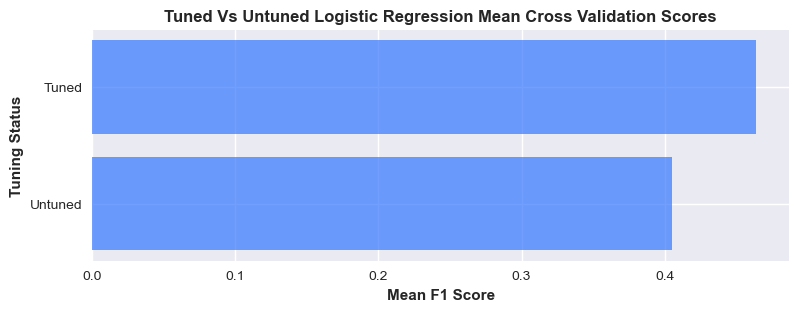

In [27]:
LR_Tuning_Statuses = ['Untuned', 'Tuned']
scores = [LR_Crossval_Untuned_Mean, LR_Crossval_Tuned_Mean]
plt.figure(figsize=(9,3))
plt.barh(LR_Tuning_Statuses, scores, color='#3377ff', 
        alpha=0.7)
plt.title("Tuned Vs Untuned Logistic Regression Mean Cross Validation Scores",
          fontweight=fontweight, fontsize=fontsize)
plt.xlabel("Mean F1 Score", fontweight=fontweight)
plt.ylabel("Tuning Status", fontweight=fontweight)
plt.show()

In [28]:
comments = 'Logistic Regression hyperparamter tuning increased mean cross validation f1 scoring.'
print(comments)

Logistic Regression hyperparamter tuning increased mean cross validation f1 scoring.


**3D: Gradient Boosting Classifier**

In [29]:
GB_Pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Gradient_Boosting', GradientBoostingClassifier(random_state=random_state,
                                            n_estimators=50, max_depth=5))])

In [30]:
GB_Crossval_Untuned= cross_val_score(GB_Pipeline, X_train, y_train, scoring='f1', cv=cv)
GB_Crossval_Untuned_Mean = GB_Crossval_Untuned.mean()
print("Untuned Gradient Boosting Cross Validation Scores:", GB_Crossval_Untuned)
print(output_divider)
print("Untuned Gradient Boosting Mean Cross Validation Score:", GB_Crossval_Untuned_Mean)

Untuned Gradient Boosting Cross Validation Scores: [0.36734694 0.3902439  0.26262626 0.44444444 0.25      ]
Untuned Gradient Boosting Mean Cross Validation Score: 0.34293230965704835


**3E: Gradient Boosting Classifer Hyperparameter Tuning**

In [31]:
gb_param_grid = {
    'Gradient_Boosting__n_estimators': [50, 100, 150],
    'Gradient_Boosting__max_depth': [None, 5, 10]
}
gb_param_search = GridSearchCV(GB_Pipeline, gb_param_grid, scoring='f1', cv=cv, verbose=2)
gb_param_search.fit(X_train, y_train)
print(output_divider)
print("Optimal Gradient Boosting Parameters:", gb_param_search.best_params_)

Fitting 5 folds for each of 9 candidates, totalling 45 fits
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=50; total time=   5.1s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=50; total time=   5.7s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=50; total time=   5.1s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=50; total time=   5.2s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=50; total time=   5.4s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=100; total time=   9.7s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=100; total time=  11.4s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=100; total time=  10.5s
[CV] END Gradient_Boosting__max_depth=None, Gradient_Boosting__n_estimators=100; total time=   9.8s
[CV] END Gradient_Boosting__max_depth=None, G

In [32]:
GB_Pipeline = Pipeline(steps=[
    ('preprocessor', data_preprocessor),
    ('Gradient_Boosting', GradientBoostingClassifier(random_state=random_state,
                                            n_estimators=100, max_depth=5))])

In [33]:
GB_Crossval_Tuned= cross_val_score(GB_Pipeline, X_train, y_train, scoring='f1', cv=cv)
GB_Crossval_Tuned_Mean = GB_Crossval_Tuned.mean()
print("Tuned Gradient Boosting Cross Validation Scores:", GB_Crossval_Tuned)
print(output_divider)
print("Tuned Gradient Boosting Mean Cross Validation Score:", GB_Crossval_Tuned_Mean)

Tuned Gradient Boosting Cross Validation Scores: [0.38       0.45238095 0.33333333 0.46464646 0.30188679]
Tuned Gradient Boosting Mean Cross Validation Score: 0.3864495085627161


**3F: Model Selection**

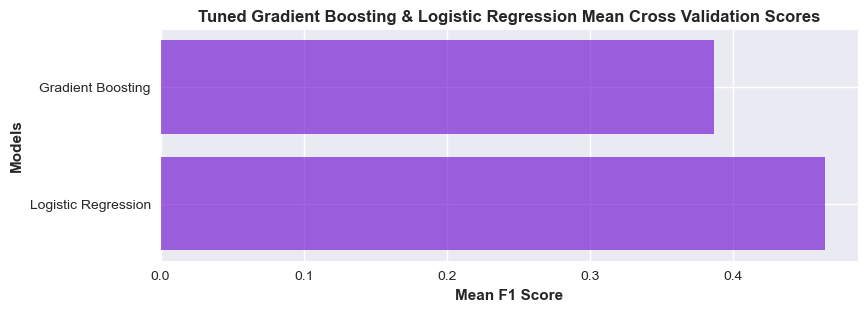

In [34]:
models = ['Logistic Regression', 'Gradient Boosting']
scores = [LR_Crossval_Tuned_Mean, GB_Crossval_Tuned_Mean]
plt.figure(figsize=(9,3))
plt.barh(models, scores, color='#6600cc', 
         alpha=0.6)
plt.title("Tuned Gradient Boosting & Logistic Regression Mean Cross Validation Scores",
          fontsize=fontsize, fontweight=fontweight)
plt.xlabel("Mean F1 Score", fontweight=fontweight)
plt.ylabel("Models", fontweight=fontweight)
plt.show()

In [35]:
comments = '''Logistic Regression will be selected as the final model as it outperformed Gradient Boosting in f1
cross validation scoring.'''
print(comments)


Logistic Regression will be selected as the final model as it outperformed Gradient Boosting in f1
cross validation scoring.


**3G: Model Fitting & Evaluation**

In [36]:
print("Fit Model To Training Data:")
print(output_divider)
LR_Pipeline.fit(X_train, y_train)

Fit Model To Training Data:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('Logistic_Regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [37]:
print("Logistic Regression Training Accuracy Score:", LR_Pipeline.score(X_train, y_train))
print(output_divider)
print("Logistic Regression Testing Accuracy Score:", LR_Pipeline.score(X_test, y_test))

Logistic Regression Training Accuracy Score: 0.7699642431466031
Logistic Regression Testing Accuracy Score: 0.7714285714285715


In [38]:
y_pred = LR_Pipeline.predict(X_test)
print("Logistic Regression Classification Report:")
print(classification_report(y_pred, y_test))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.95      0.85       439
           1       0.77      0.35      0.48       191

    accuracy                           0.77       630
   macro avg       0.77      0.65      0.67       630
weighted avg       0.77      0.77      0.74       630



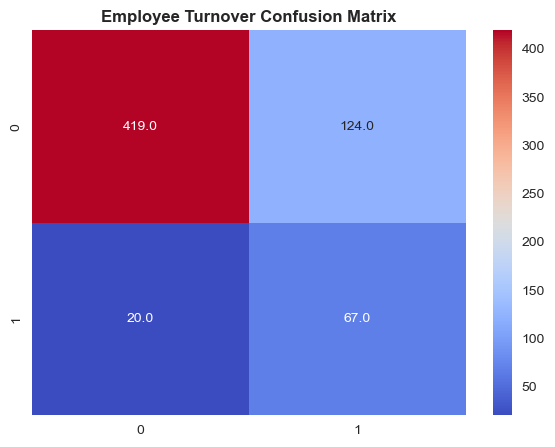

In [39]:
Confusion_Matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7,5))
sns.heatmap(Confusion_Matrix, annot=True, fmt='.1f', cmap='coolwarm')
plt.title("Employee Turnover Confusion Matrix",
          fontsize=fontsize, fontweight=fontweight)
plt.show()

**Project Findings:** Logistic Regression was selected as the final model as it outperformed Gradient Boosting in cross validation
scoring. Hyperparameter tuning proved useful as optimizing class weight, solver type, and C value increased model performace. A precision score of .77 
indicates the model correctly classfied 486 out of 630 employees. The model demonstrated reasonable overall accuracy and strong performance in predicting employee retention. Additionally, the model achieved similar accuracy scores with training and testing data indicating no obvious signs of overfitting. While the model provides a useful baseline for attrition prediction, improvements in recall would be needed for more reliable identification of potential departures.